In [7]:
from pathlib import Path
import sys

# Project root: parent directory of notebooks
PROJECT_ROOT = Path.cwd().parent

# Add src directory to Python path
SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print("Project Root:", PROJECT_ROOT)
print("Source Path:", SRC_PATH)
print("Project Root Exists:", PROJECT_ROOT.exists())

Project Root: d:\karnaphuli-shm-month2
Source Path: d:\karnaphuli-shm-month2\src
Project Root Exists: True


In [8]:
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "month2_final_dataset.csv"

print("Dataset Path:", DATA_PATH)
print("File Exists:", DATA_PATH.exists())

Dataset Path: d:\karnaphuli-shm-month2\data\raw\month2_final_dataset.csv
File Exists: True


In [9]:
import importlib
import data_loader

importlib.reload(data_loader)

from data_loader import load_data

df = load_data(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (3483, 30)
Columns: ['accel_x', 'accel_y', 'accel_z', 'boot_id', 'device_id', 'device_timestamp_ms', 'dht_valid', 'gateway_id', 'humidity', 'hx711_valid', 'latency_ms', 'latency_valid', 'load_calibrated', 'load_gram', 'load_kg', 'load_raw', 'mpu_valid', 'quality_flag', 'received_at', 'sequence_number', 'session_id', 'temperature', 'water_raw', 'wifi_reconnect_count', 'zone_id', 'record_index', 'device_timestamp_valid', 'boot_id_status', 'load_calibration_status', 'latency_audit_valid']


In [10]:
df.head()

,accel_x,accel_y,accel_z,boot_id,device_id,device_timestamp_ms,dht_valid,gateway_id,humidity,hx711_valid,...,session_id,temperature,water_raw,wifi_reconnect_count,zone_id,record_index,device_timestamp_valid,boot_id_status,load_calibration_status,latency_audit_valid
0,0.175,-0.022,10.879,NaN,ESP32-GW-LAB-001,1793684285798,True,gateway01,81.8,True,...,SHM-TEST-001,31.6,0,2,LAB_PROTOTYPE,1,True,missing,missing,True
1,0.184,0.022,10.879,NaN,ESP32-GW-LAB-001,1793684301591,True,gateway01,81.7,True,...,SHM-TEST-001,31.5,0,2,LAB_PROTOTYPE,2,True,missing,missing,True
2,0.156,0.072,10.846,NaN,ESP32-GW-LAB-001,1793684302596,True,gateway01,81.7,True,...,SHM-TEST-001,31.5,0,2,LAB_PROTOTYPE,3,True,missing,missing,True
3,0.141,0.026,10.877,NaN,ESP32-GW-LAB-001,1793684334386,True,gateway01,81.8,True,...,SHM-TEST-001,31.5,0,2,LAB_PROTOTYPE,4,True,missing,missing,True
4,0.201,-0.014,10.920,NaN,ESP32-GW-LAB-001,1793684324520,True,gateway01,81.9,True,...,SHM-TEST-001,31.5,0,2,LAB_PROTOTYPE,5,True,missing,missing,True


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3483 entries, 0 to 3482
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   accel_x                  3483 non-null   float64            
 1   accel_y                  3483 non-null   float64            
 2   accel_z                  3483 non-null   float64            
 3   boot_id                  285 non-null    float64            
 4   device_id                3483 non-null   str                
 5   device_timestamp_ms      3483 non-null   int64              
 6   dht_valid                3483 non-null   bool               
 7   gateway_id               3483 non-null   str                
 8   humidity                 3483 non-null   float64            
 9   hx711_valid              3483 non-null   bool               
 10  latency_ms               3483 non-null   float64            
 11  latency_valid            3483 non-null   

In [12]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
accel_x,3483.0,NaN,NaN,NaN,0.179483,0.069,0.156,0.177,0.204,0.402,0.034897
accel_y,3483.0,NaN,NaN,NaN,0.019997,-0.108,0.0,0.019,0.041,0.151,0.033077
accel_z,3483.0,NaN,NaN,NaN,10.956409,10.623,10.903,10.958,11.011,11.265,0.073304
boot_id,285.0,NaN,NaN,NaN,3294754968.0,3294754968.0,3294754968.0,3294754968.0,3294754968.0,3294754968.0,0.0
device_id,3483,1,ESP32-GW-LAB-001,3483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_timestamp_ms,3483.0,NaN,NaN,NaN,1749289013237.408936,0.0,1793948091584.0,1794161431021.0,1794243805482.0,1794245734490.0,280026924387.680847
dht_valid,3483,1,True,3483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gateway_id,3483,1,gateway01,3483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
humidity,3483.0,NaN,NaN,NaN,80.389951,72.3,76.7,78.5,83.3,90.9,4.901872
hx711_valid,3483,2,True,3480,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Missing Value Analysis

missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("Total missing values:", df.isnull().sum().sum())
print("\nMissing Value Report:")

display(missing_report)

Total missing values: 6110

Missing Value Report:


,Missing_Count,Missing_Percentage
boot_id,3198,91.817399
load_calibrated,1456,41.803043
load_gram,1456,41.803043


In [14]:
# Exact duplicate records

total_duplicates = df.duplicated().sum()

print("Total records:", len(df))
print("Duplicate records:", total_duplicates)
print("Unique records:", len(df) - total_duplicates)

Total records: 3483
Duplicate records: 0
Unique records: 3483


In [15]:
# Quality distribution

quality_counts = df["quality_flag"].value_counts(
    dropna=False
)

quality_percentage = (
    df["quality_flag"].value_counts(
        normalize=True,
        dropna=False
    ) * 100
)

quality_report = pd.DataFrame({
    "Count": quality_counts,
    "Percentage": quality_percentage
})

display(quality_report)

,Count,Percentage
quality_flag,,
partial,2412,69.250646
ok,1068,30.663221
degraded,3,0.086133


In [16]:
validity_columns = [
    "dht_valid",
    "mpu_valid",
    "hx711_valid",
    "latency_valid",
    "device_timestamp_valid",
    "latency_audit_valid",
    "load_calibrated"
]

for col in validity_columns:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False))


dht_valid
dht_valid
True    3483
Name: count, dtype: int64

mpu_valid
mpu_valid
True    3483
Name: count, dtype: int64

hx711_valid
hx711_valid
True     3480
False       3
Name: count, dtype: int64

latency_valid
latency_valid
False    1754
True     1729
Name: count, dtype: int64

device_timestamp_valid
device_timestamp_valid
True     3396
False      87
Name: count, dtype: int64

latency_audit_valid
latency_audit_valid
False    1754
True     1729
Name: count, dtype: int64

load_calibrated
load_calibrated
NaN      1456
True     1068
False     959
Name: count, dtype: int64


In [17]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().sum() / len(df) * 100
    )
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_report)

print("Total missing:", missing_report["Missing_Count"].sum())

,Missing_Count,Missing_Percentage
boot_id,3198,91.817399
load_calibrated,1456,41.803043
load_gram,1456,41.803043


Total missing: 6110


In [18]:
# Sensor columns for IQR analysis

sensor_columns = [
    "temperature",
    "humidity",
    "accel_x",
    "accel_y",
    "accel_z",
    "water_raw",
    "load_kg",
    "load_gram"
]

outlier_results = []

for col in sensor_columns:

    series = df[col].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = series[
        (series < lower_bound) |
        (series > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(series) * 100
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report.round(3))

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,temperature,27.200,29.700,2.500,23.450,33.450,0,0.000
1,humidity,76.700,83.300,6.600,66.800,93.200,0,0.000
2,accel_x,0.156,0.204,0.048,0.084,0.276,19,0.546
3,accel_y,0.000,0.041,0.041,-0.062,0.103,44,1.263
4,accel_z,10.903,11.011,0.108,10.741,11.173,7,0.201
5,water_raw,0.000,0.000,0.000,0.000,0.000,107,3.072
6,load_kg,0.000,0.204,0.204,-0.305,0.509,0,0.000
7,load_gram,0.000,205.985,205.985,-308.978,514.963,0,0.000


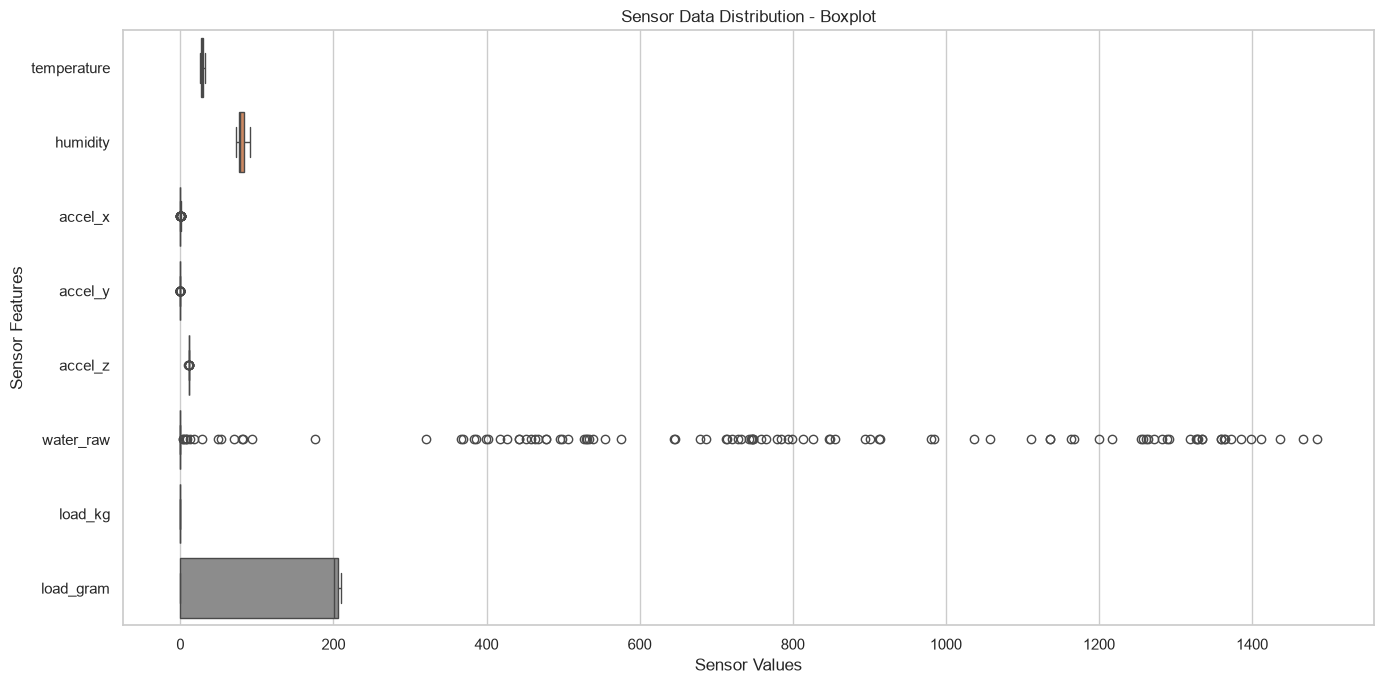

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df[sensor_columns],
    orient="h"
)

plt.title("Sensor Data Distribution - Boxplot")
plt.xlabel("Sensor Values")
plt.ylabel("Sensor Features")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs" / "sensor_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
calibration_check = pd.crosstab(
    df["load_calibrated"].astype("string").fillna("MISSING"),
    df["load_gram"].isna(),
    rownames=["load_calibrated"],
    colnames=["load_gram_missing"]
)

display(calibration_check)

load_gram_missing,False,True
load_calibrated,,
False,959,0
MISSING,0,1456
True,1068,0


In [21]:
calibration_data = pd.DataFrame({
    "Reference_Weight_g": [100, 200, 500, 1000],
    "Mean_Measured_g": [
        99.363,
        200.249,
        501.252,
        861.954
    ],
    "Mean_Error_g": [
        -0.637,
        0.249,
        1.252,
        -138.046
    ],
    "Mean_Absolute_Error_Percentage": [
        0.637,
        0.184,
        0.250,
        13.805
    ]
})

display(calibration_data)

,Reference_Weight_g,Mean_Measured_g,Mean_Error_g,Mean_Absolute_Error_Percentage
0,100,99.363,-0.637,0.637
1,200,200.249,0.249,0.184
2,500,501.252,1.252,0.250
3,1000,861.954,-138.046,13.805


In [23]:
from pathlib import Path

# Detect project root automatically
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Define output directory
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Create directory if it does not exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Output Directory:", OUTPUT_DIR)
print("Output directory is ready!")

Project Root: d:\karnaphuli-shm-month2
Output Directory: d:\karnaphuli-shm-month2\outputs
Output directory is ready!


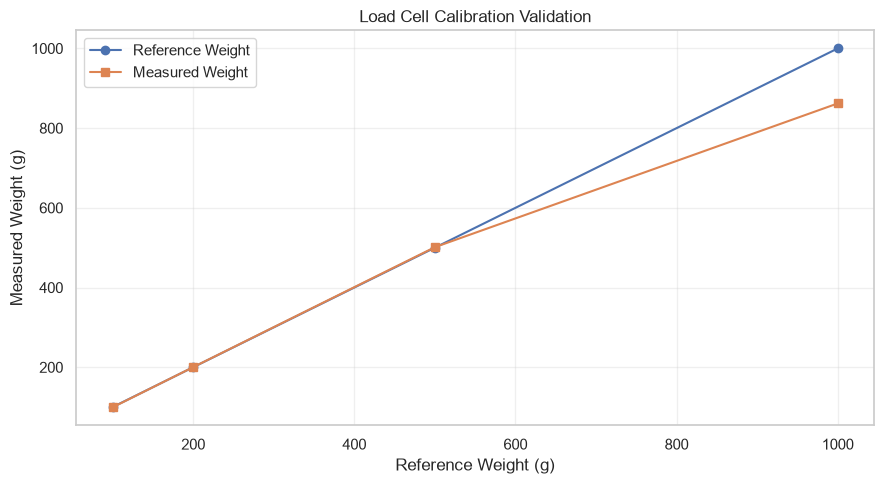

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    calibration_data["Reference_Weight_g"],
    calibration_data["Reference_Weight_g"],
    marker="o",
    label="Reference Weight"
)

plt.plot(
    calibration_data["Reference_Weight_g"],
    calibration_data["Mean_Measured_g"],
    marker="s",
    label="Measured Weight"
)

plt.title("Load Cell Calibration Validation")
plt.xlabel("Reference Weight (g)")
plt.ylabel("Measured Weight (g)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "load_cell_calibration_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
sensor_columns = [
    "temperature",
    "humidity",
    "accel_x",
    "accel_y",
    "accel_z",
    "water_raw",
    "load_kg",
    "load_gram"
]

outlier_results = []

for col in sensor_columns:

    series = df[col].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = series[
        (series < lower_bound) |
        (series > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(series) * 100
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report.round(3))

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,temperature,27.200,29.700,2.500,23.450,33.450,0,0.000
1,humidity,76.700,83.300,6.600,66.800,93.200,0,0.000
2,accel_x,0.156,0.204,0.048,0.084,0.276,19,0.546
3,accel_y,0.000,0.041,0.041,-0.062,0.103,44,1.263
4,accel_z,10.903,11.011,0.108,10.741,11.173,7,0.201
5,water_raw,0.000,0.000,0.000,0.000,0.000,107,3.072
6,load_kg,0.000,0.204,0.204,-0.305,0.509,0,0.000
7,load_gram,0.000,205.985,205.985,-308.978,514.963,0,0.000


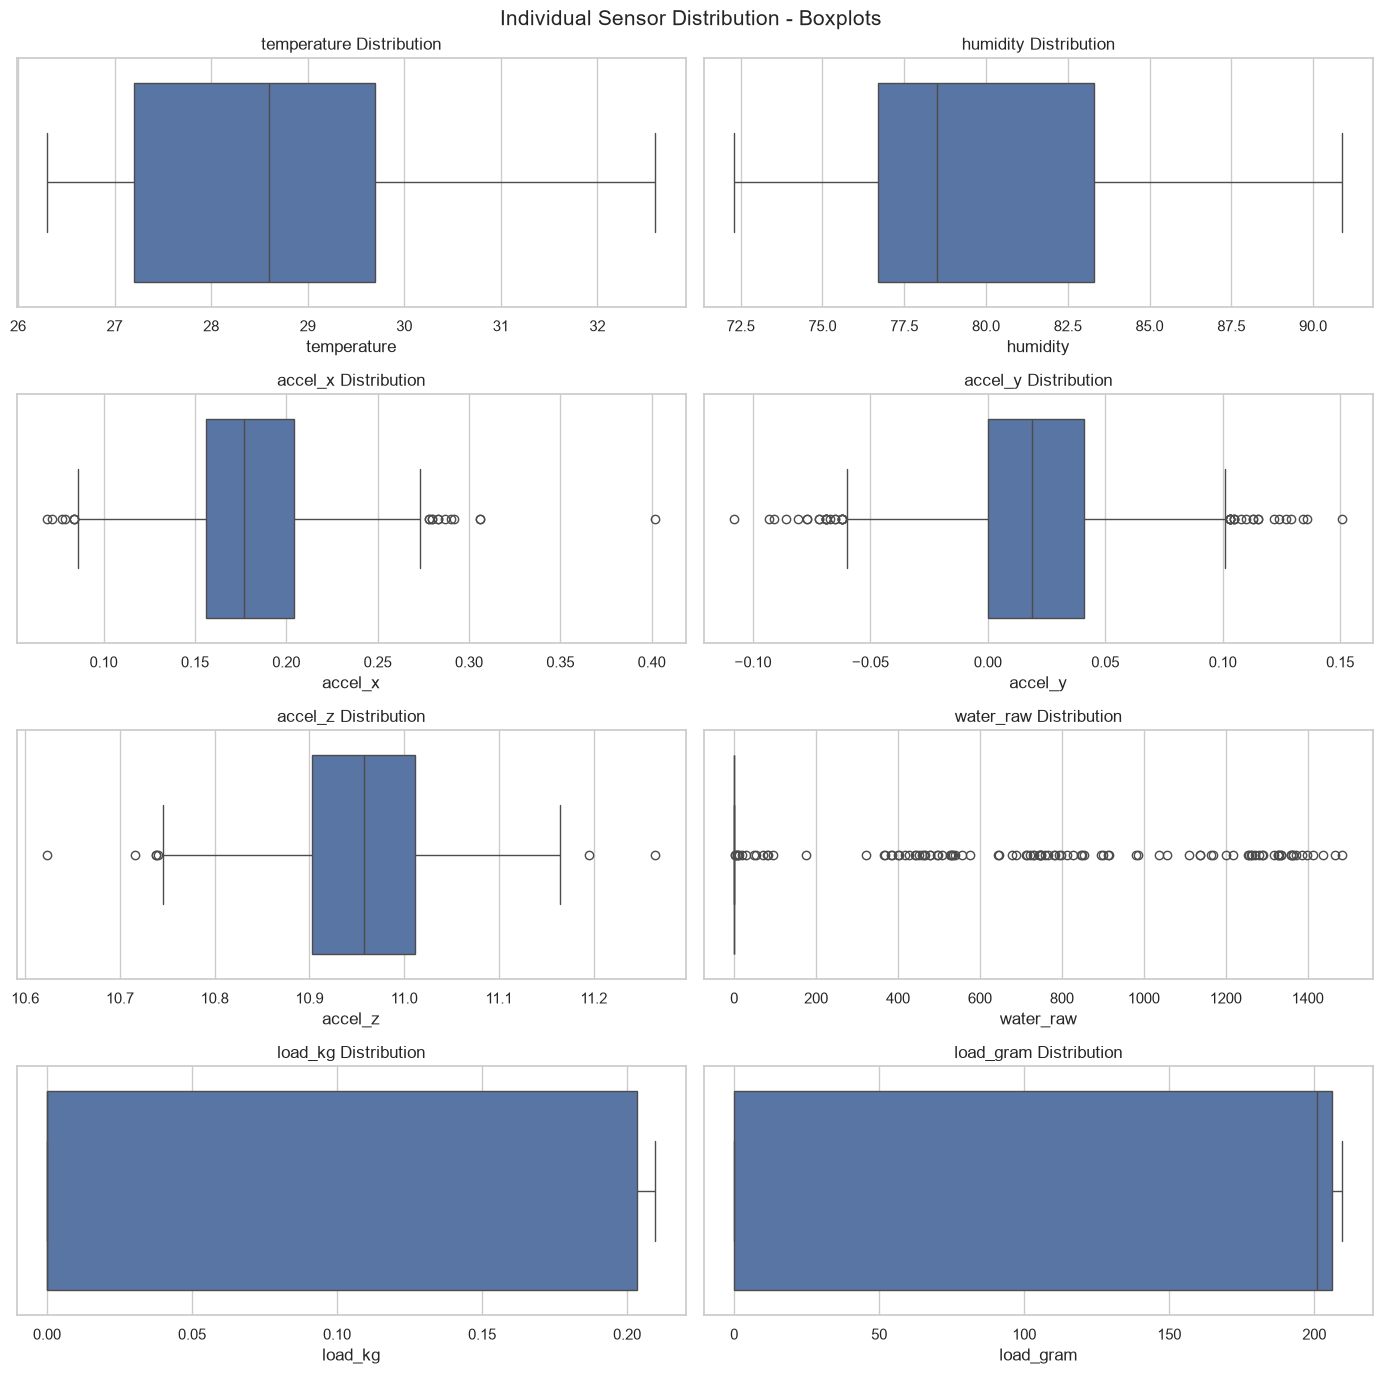

In [26]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 14)
)

for ax, col in zip(axes.flat, sensor_columns):

    sns.boxplot(
        x=df[col],
        ax=ax
    )

    ax.set_title(f"{col} Distribution")
    ax.set_xlabel(col)

plt.suptitle(
    "Individual Sensor Distribution - Boxplots",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sensor_boxplots_individual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
print("Device timestamp statistics:")
display(df["device_timestamp_ms"].describe())

print("\nLatency statistics:")
display(df["latency_ms"].describe())

print("\nTimestamp validity:")
print(
    df["device_timestamp_valid"].value_counts(
        dropna=False
    )
)

print("\nLatency validity:")
print(
    df["latency_valid"].value_counts(
        dropna=False
    )
)

print("\nLatency audit validity:")
print(
    df["latency_audit_valid"].value_counts(
        dropna=False
    )
)

Device timestamp statistics:


count    3.483000e+03
mean     1.749289e+12
std      2.800269e+11
min      0.000000e+00
25%      1.793948e+12
50%      1.794161e+12
75%      1.794244e+12
max      1.794246e+12
Name: device_timestamp_ms, dtype: float64


Latency statistics:


count    3.483000e+03
mean     4.480510e+10
std      2.799716e+11
min     -1.371606e+03
25%     -5.395870e+02
50%      9.794000e+00
75%      4.711045e+02
max      1.793813e+12
Name: latency_ms, dtype: float64


Timestamp validity:
device_timestamp_valid
True     3396
False      87
Name: count, dtype: int64

Latency validity:
latency_valid
False    1754
True     1729
Name: count, dtype: int64

Latency audit validity:
latency_audit_valid
False    1754
True     1729
Name: count, dtype: int64


In [29]:
# Generate descriptive statistics

descriptive_statistics = df.describe(include="all").T

print("Descriptive Statistics Generated Successfully!")
display(descriptive_statistics)

Descriptive Statistics Generated Successfully!


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
accel_x,3483.0,NaN,NaN,NaN,0.179483,0.069,0.156,0.177,0.204,0.402,0.034897
accel_y,3483.0,NaN,NaN,NaN,0.019997,-0.108,0.0,0.019,0.041,0.151,0.033077
accel_z,3483.0,NaN,NaN,NaN,10.956409,10.623,10.903,10.958,11.011,11.265,0.073304
boot_id,285.0,NaN,NaN,NaN,3294754968.0,3294754968.0,3294754968.0,3294754968.0,3294754968.0,3294754968.0,0.0
device_id,3483,1,ESP32-GW-LAB-001,3483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_timestamp_ms,3483.0,NaN,NaN,NaN,1749289013237.408936,0.0,1793948091584.0,1794161431021.0,1794243805482.0,1794245734490.0,280026924387.680847
dht_valid,3483,1,True,3483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gateway_id,3483,1,gateway01,3483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
humidity,3483.0,NaN,NaN,NaN,80.389951,72.3,76.7,78.5,83.3,90.9,4.901872
hx711_valid,3483,2,True,3480,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
# Save descriptive statistics

descriptive_statistics.to_csv(
    OUTPUT_DIR / "descriptive_statistics.csv"
)

print("Descriptive statistics saved successfully!")

Descriptive statistics saved successfully!


In [32]:
# Generate sensor validity report

validity_columns = [
    "dht_valid",
    "mpu_valid",
    "hx711_valid",
    "latency_valid",
    "device_timestamp_valid",
    "latency_audit_valid",
    "load_calibrated"
]

validity_rows = []

for col in validity_columns:
    if col in df.columns:
        counts = df[col].value_counts(dropna=False)

        for value, count in counts.items():
            validity_rows.append({
                "column": col,
                "status": str(value),
                "count": int(count),
                "percentage": round(
                    (count / len(df)) * 100, 2
                )
            })

validity_report = pd.DataFrame(validity_rows)

display(validity_report)

print("Sensor validity report generated successfully!")

,column,status,count,percentage
0,dht_valid,True,3483,100.00
1,mpu_valid,True,3483,100.00
2,hx711_valid,True,3480,99.91
3,hx711_valid,False,3,0.09
4,latency_valid,False,1754,50.36
5,latency_valid,True,1729,49.64
6,device_timestamp_valid,True,3396,97.50
7,device_timestamp_valid,False,87,2.50
8,latency_audit_valid,False,1754,50.36
9,latency_audit_valid,True,1729,49.64


Sensor validity report generated successfully!


In [33]:
required_variables = [
    "descriptive_statistics",
    "missing_report",
    "quality_report",
    "validity_report",
    "calibration_data",
    "calibration_check",
    "outlier_report"
]

for variable in required_variables:
    print(
        f"{variable}:",
        "Available" if variable in globals() else "Missing"
    )

descriptive_statistics: Available
missing_report: Available
quality_report: Available
validity_report: Available
calibration_data: Available
calibration_check: Available
outlier_report: Available


In [34]:
# Save descriptive statistics
descriptive_statistics.to_csv(
    OUTPUT_DIR / "descriptive_statistics.csv"
)

# Save missing values
missing_report.to_csv(
    OUTPUT_DIR / "missing_value_report.csv"
)

# Save quality distribution
quality_report.to_csv(
    OUTPUT_DIR / "quality_report.csv"
)

# Save validity report
validity_report.to_csv(
    OUTPUT_DIR / "sensor_validity_report.csv",
    index=False
)

# Save calibration validation
calibration_data.to_csv(
    OUTPUT_DIR / "load_cell_calibration_validation.csv",
    index=False
)

# Save calibration metadata consistency
calibration_check.to_csv(
    OUTPUT_DIR / "calibration_metadata_check.csv"
)

# Save outlier report
outlier_report.to_csv(
    OUTPUT_DIR / "outlier_report.csv",
    index=False
)

print("All EDA reports saved successfully!")

All EDA reports saved successfully!
